# Основы глубинного обучения, майнор ИАД

## Домашнее задание 1: полносвязные сети

**ФИО:** Артемьев Никита Константинович

**Факт о себе:** Люблю пиво!


## Общая информация

__Дата выдачи:__ 28.09.2026

__Мягкий дедлайн:__ 23:59MSK 18.10.2026

__Жесткий дедлайн:__ 23:59MSK 25.10.2026


## Оценивание и штрафы

Максимально допустимая оценка за работу — 10 баллов. Сдавать задание после указанного срока сдачи нельзя.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов. Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).  Если два студента сгенерировали в нейронке одинаковые либо похожие решения, это считается плагиатом и приводит к обнулению обеих работ.

Неэффективная реализация кода может негативно отразиться на оценке. Также оценка может быть снижена за плохо читаемый код и плохо оформленные графики. Все ответы должны сопровождаться кодом или комментариями о том, как они были получены.

Итогова оценка считается как

$$
min(part_1, part_2) \cdot 0.6 + max(part_1, part_2) \cdot 0.2 + part_3 \cdot 0.2
$$

где $part_1$, $part_2$ и $part_3$ - оценки за первую, вторую и третью части работы

> Также, за домашнее задание выставляется 0, если не сделано нулевое задание либо нет подробного описания ваших экспериментов в третьей части.

## Оформление

1. Обязательно фиксируйте зерно генератора случайных чисел в экспериментах. При перезапуске кода значения не должны меняться.
2. Вверху файла подпишите фамилию, имя и какой-то занимательный факт о себе.
3. Обратите внимание, что у графиков должны быть подписаны оси, заголовок графика и при необходимости обязательно наличие легенды. 

> За отсутствие названий графиков и подписей к осям могут снижаться баллы. Все картинки должны быть самодостаточны и визуально удобны для восприятия, так чтобы не нужно было смотреть ваш код или знать задание, чтобы понять что на них изображено.

Из каждого проведённого эксперимента делайте выводы и фиксируйте их. Эти выводы не должны быть поверхностными и очевидными. Не будьте мудрым королём.

<br>

<center>
<img src="https://raw.githubusercontent.com/hse-ds/iad-deep-learning/refs/heads/master/2025/homeworks/king.png" width="300"> 
</center>

**Пример плохого вывода:** Синенькая линия идет вверх, а красная вниз. Черненькая идет вниз, а потом вверх. 

<br>

<center>
<img src="https://raw.githubusercontent.com/hse-ds/iad-deep-learning/refs/heads/master/2025/homeworks/bad_lines.png" width="600"> 
</center>

## О задании

Вам предстоит обучить полносвязную нейронную сеть для предсказания года выпуска песни по ее аудио-признакам. Для этого мы будем использовать [Million Songs Dataset](https://samyzaf.com/ML/song_year/song_year.html).

In [2]:
import torch
from torch import nn
import torch.nn.functional as F

import pandas as pd
import numpy as np
import random

from tqdm.notebook import tqdm
from IPython.display import clear_output
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

Начнем с того, что скачаем и загрузим данные:

In [3]:
# !wget -O yearpredictionmsd.zip https://archive.ics.uci.edu/static/public/203/yearpredictionmsd.zip

In [4]:
df = pd.read_csv('yearpredictionmsd.zip', header=None)
df.head()

,0,1,2,3,4,5,6,7,8,9,...,81,82,83,84,85,86,87,88,89,90
0,2001,49.94357,21.47114,73.07750,8.74861,-17.40628,-13.09905,-25.01202,-12.23257,7.83089,...,13.01620,-54.40548,58.99367,15.37344,1.11144,-23.08793,68.40795,-1.82223,-27.46348,2.26327
1,2001,48.73215,18.42930,70.32679,12.94636,-10.32437,-24.83777,8.76630,-0.92019,18.76548,...,5.66812,-19.68073,33.04964,42.87836,-9.90378,-32.22788,70.49388,12.04941,58.43453,26.92061
2,2001,50.95714,31.85602,55.81851,13.41693,-6.57898,-18.54940,-3.27872,-2.35035,16.07017,...,3.03800,26.05866,-50.92779,10.93792,-0.07568,43.20130,-115.00698,-0.05859,39.67068,-0.66345
3,2001,48.24750,-1.89837,36.29772,2.58776,0.97170,-26.21683,5.05097,-10.34124,3.55005,...,34.57337,-171.70734,-16.96705,-46.67617,-12.51516,82.58061,-72.08993,9.90558,199.62971,18.85382
4,2001,50.97020,42.20998,67.09964,8.46791,-15.85279,-16.81409,-12.48207,-9.37636,12.63699,...,9.92661,-55.95724,64.92712,-17.72522,-1.49237,-7.50035,51.76631,7.88713,55.66926,28.74903


Посмотрим на статистики по данным.

In [5]:
df.describe()

,0,1,2,3,4,5,6,7,8,9,...,81,82,83,84,85,86,87,88,89,90
count,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,...,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000
mean,1998.397082,43.387126,1.289554,8.658347,1.164124,-6.553601,-9.521975,-2.391089,-1.793236,3.727876,...,15.755406,-73.461500,41.542422,37.934119,0.315751,17.669213,-26.315336,4.458641,20.035136,1.329105
std,10.931046,6.067558,51.580351,35.268585,16.322790,22.860785,12.857751,14.571873,7.963827,10.582861,...,32.099635,175.618889,122.228799,95.050631,16.161764,114.427905,173.977336,13.346557,185.558247,22.088576
min,1922.000000,1.749000,-337.092500,-301.005060,-154.183580,-181.953370,-81.794290,-188.214000,-72.503850,-126.479040,...,-437.722030,-4402.376440,-1810.689190,-3098.350310,-341.789120,-3168.924570,-4319.992320,-236.039260,-7458.378150,-381.424430
25%,1994.000000,39.954690,-26.059520,-11.462710,-8.487500,-20.666450,-18.440990,-10.780600,-6.468420,-2.293660,...,-1.812650,-139.555160,-20.986900,-4.669540,-6.781590,-31.580610,-101.530300,-2.566090,-59.509270,-8.820210
50%,2002.000000,44.258500,8.417850,10.476320,-0.652840,-6.007770,-11.188390,-2.046670,-1.736450,3.822310,...,9.171850,-53.090060,28.791060,33.623630,0.820840,15.598470,-21.204120,3.117640,7.759730,0.053050
75%,2006.000000,47.833890,36.124010,29.764820,8.787540,7.741870,-2.388960,6.508580,2.913450,9.961820,...,26.274480,13.478730,89.661770,77.785800,8.470990,67.794960,52.389330,9.967740,86.351610,9.679520
max,2011.000000,61.970140,384.065730,322.851430,335.771820,262.068870,166.236890,172.402680,126.741270,146.297950,...,840.973380,4469.454870,3210.701700,1734.079690,260.544900,3662.065650,2833.608950,463.419500,7393.398440,677.899630


Целевая переменная, год выпуска песни, записана в первом столбце. Посмотрим на ее распределение.

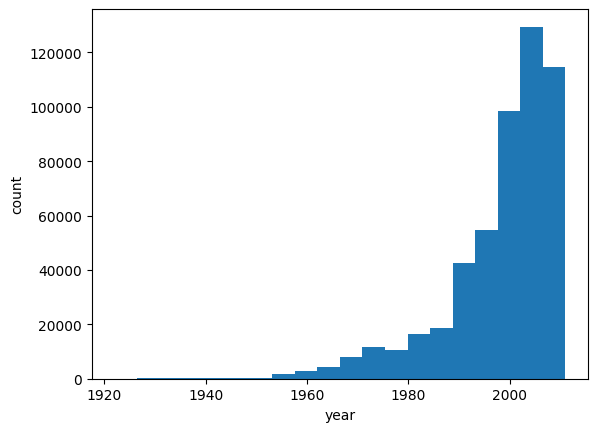

Range: 1922 - 2011
Unique values: 89


In [6]:
plt.hist(df.iloc[:, 0], bins=20)
plt.xlabel('year')
plt.ylabel('count')
plt.show()
print(f'Range: {df.iloc[:, 0].min()} - {df.iloc[:, 0].max()}')
print(f'Unique values: {np.unique(df.iloc[:, 0]).size}')

Разобьем данные на обучение и тест (не меняйте здесь ничего, чтобы сплит был одинаковым у всех).

In [7]:
X = df.iloc[:, 1:].values
y = df.iloc[:, 0].values

train_size = int(0.75 * X.shape[0])

X_train = X[:train_size, :]
y_train = y[:train_size]
X_test = X[train_size:, :]
y_test = y[train_size:]

X_train.shape, X_test.shape

((386508, 90), (128837, 90))

## Полезные советы:

- Если вы сразу реализуете обучение на GPU, то у вас будет больше времени на эксперименты, так как любые вычисления будут работать быстрее. Google Colab предоставляет несколько GPU-часов (обычно около 8-10) в сутки бесплатно.

- Если вы чего-то не знаете, не стесняйтесь гуглить. В интернете очень много полезной информации, туториалов и советов по глубинному обучению и `pytorch`. Но не забывайте, что за списанный код без ссылки на источник последует наказание.

- Чтобы отладить код, можете обучаться на небольшой части данных или даже на одном батче. Если лосс на обучающей выборке не падает, то что-то точно идет не так.

- Пользуйтесь утилитами, которые вам предоставляет `pytorch` (например, `Dataset` и `Dataloader`). Их специально разработали для упрощения разработки пайплайна обучения.

- Скорее всего, вы захотите отслеживать прогресс обучения. Для создания прогресс-баров есть удобная библиотека `tqdm`.

- Быть может, вы захотите, чтобы графики рисовались прямо во время обучения. Можете воспользоваться функцией [clear_output](http://ipython.org/ipython-doc/dev/api/generated/IPython.display.html#IPython.display.clear_output), чтобы удалять старый график и рисовать новый на его месте.

- При желании вы можете логгировать метрики обучения и свои эксперименты в WandB либо любой другой сервис. Не забудьте приложить к тетрадке ссылку на результаты экспериментов либо скришноты графиков с пояснениями, что проверяющий должен на них увидеть.

- Финальное значение тестовой метрики для удобства проверки выведите в тетрадке.

## Задание 0 (0 баллов, но при невыполнении максимальная оценка за всю работу &mdash; 0 баллов)

Мы будем использовать RMSE как метрику качества. Прежде чем обучать нейронные сети, нам нужно проверить несколько простых бейзлайнов, чтобы было с чем сравнить более сложные алгоритмы. Для этого бучите `Ridge` регрессию из `sklearn`. Кроме того, посчитайте качество при наилучшем константном прогнозе.

Для выполнения данного задания (и всех последующих) предобработайте данные.

1. Зафиксируйте random_seed везде где только возможно. Вам предоставлена функция для этого, однако вы можете дополнить ее своими дополнениями.
2. Обучите `StandertScaler` и предобработайте ваши данные. В следующих заданиях можете использовать другой `scaler` или вообще отказаться от него.


In [8]:
def set_global_seed(seed: int) -> None:
    """Set global seed for reproducibility.
    :param int seed: Seed to be set
    """
    torch.backends.cudnn.deterministic = True
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)

    # также можно зафиксировать seed для Dataloader
    g = torch.Generator()
    g.manual_seed(seed)
    return g

# Сид для каждого worker в Dataloader
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = set_global_seed(42)

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = Ridge(random_state=42)
model.fit(X_train_scaled, y_train)
predict = model.predict(X_test_scaled)

rmse_for_model = np.sqrt(np.mean((y_test - predict) ** 2))
print(rmse_for_model)

9.47363033268409


Лучшая константа для RMSE это среднее. Используйте среднее, расчитанное на трэйне в качестве прогноза для теста и посчитайте для такой наивной модели RMSE.

In [10]:
best_rmse_metric = np.sqrt(np.mean((y_test - y_train.mean()) ** 2))
print(best_rmse_metric)

10.845542969687791


Теперь приступим к экспериментам с нейросетями. Для начала отделим от данных валидацию. Тестовую выборку мы будем использовать только для того, чтобы измерить итоговую метрику качества модели.

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=0xE2E4)
X_val_scaled = scaler.transform(X_val)
X_train.shape, X_val.shape

((289881, 90), (96627, 90))

## Часть I. Обучаем линейную регрессию (максимум 10 баллов)

**Задание 1 (10 баллов):** Обучите в `pytorch` линейную регрессию. 

- Создайте модель линейной регрессии, которая будет состоять только из одного `Linear()` слоя.
   
- Напишите цикл обучения вашей линейной регрессии. В нем реализуйте подсчет функции потерь, сделайте шаг градиентного спуска. Запрещено использовать готовые оптимизаторы и loss-функции из библиотеки `pytorch`. Для подсчета градиента воспользуйтесь методом backward.
   
- Запустите обучение на 10 эпохах, после каждой проверяйте значение целевой метрики на тестовой выборке.
   
- Выведите на экран графики метрики и значения функции потерь на тестовой и обучающей выборке.

В данном задании нет цели побить какой-то порог по метрике. Ваша задача &mdash; убедиться в том, что ваш рукописный цикл обучения работает. Для ускорения вычислений и обучения модели можете брать только срез данных, а не весь датасет.

In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32, device=device)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32, device=device).reshape(-1, 1)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32, device=device)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32, device=device).reshape(-1, 1)

In [13]:
def mse_loss(pred, target):
    return ((pred - target) ** 2).mean()

def sgd_step(model, lr):
    with torch.no_grad():
        for parametr in model.parameters():
            parametr -= lr * parametr.grad
            parametr.grad = None

def train_epoch(model, X, y, lr, batch_size, generator):
    n = X.shape[0]
    perm = torch.randperm(n, generator=generator)
    for start in range(0, n, batch_size):
        idx = perm[start:start + batch_size]
        loss = mse_loss(model(X[idx]), y[idx])
        loss.backward()
        sgd_step(model, lr)

@torch.no_grad()
def evaluate(model, X, y):
    loss = mse_loss(model(X), y)
    return loss.item(), torch.sqrt(loss).item()

In [14]:
g = set_global_seed(42)
model = nn.Linear(X_train_tensor.shape[1], 1).to(device)
with torch.no_grad():
    model.bias.fill_(y_train_tensor.mean())

lr = 1e-3
batch_size = 256
epochs = 10

train_losses, test_losses = [], []
train_rmses, test_rmses = [], []

for epoch in range(1, epochs + 1):
    train_epoch(model, X_train_tensor, y_train_tensor, lr, batch_size, g)

    train_loss, train_rmse = evaluate(model, X_train_tensor, y_train_tensor)
    test_loss, test_rmse = evaluate(model, X_test_tensor, y_test_tensor)
    
    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_rmses.append(train_rmse)
    test_rmses.append(test_rmse)

    print(f"epoch {epoch:02d}  train MSE {train_loss:.2f}  test MSE {test_loss:.2f}  "
          f"train RMSE {train_rmse:.3f}  test RMSE {test_rmse:.3f}")

epoch 01  train MSE 95.31  test MSE 93.76  train RMSE 9.763  test RMSE 9.683
epoch 02  train MSE 92.85  test MSE 91.25  train RMSE 9.636  test RMSE 9.552
epoch 03  train MSE 92.11  test MSE 90.43  train RMSE 9.597  test RMSE 9.510
epoch 04  train MSE 91.80  test MSE 90.15  train RMSE 9.581  test RMSE 9.495
epoch 05  train MSE 91.72  test MSE 90.07  train RMSE 9.577  test RMSE 9.490
epoch 06  train MSE 91.61  test MSE 89.91  train RMSE 9.571  test RMSE 9.482
epoch 07  train MSE 91.59  test MSE 89.88  train RMSE 9.570  test RMSE 9.481
epoch 08  train MSE 91.57  test MSE 89.86  train RMSE 9.569  test RMSE 9.480
epoch 09  train MSE 91.56  test MSE 89.83  train RMSE 9.569  test RMSE 9.478
epoch 10  train MSE 91.56  test MSE 89.84  train RMSE 9.569  test RMSE 9.479


In [15]:
for epoch in range(1, epochs + 1):
    train_epoch(model, X_train_tensor, y_train_tensor, lr, batch_size, g)

    train_loss, train_rmse = evaluate(model, X_train_tensor, y_train_tensor)
    test_loss, test_rmse = evaluate(model, X_test_tensor, y_test_tensor)
    
    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_rmses.append(train_rmse)
    test_rmses.append(test_rmse)

    print(f"epoch {epoch:02d}  train MSE {train_loss:.2f}  test MSE {test_loss:.2f}  "
          f"train RMSE {train_rmse:.3f}  test RMSE {test_rmse:.3f}")

epoch 01  train MSE 91.57  test MSE 89.83  train RMSE 9.569  test RMSE 9.478
epoch 02  train MSE 91.56  test MSE 89.83  train RMSE 9.569  test RMSE 9.478
epoch 03  train MSE 91.55  test MSE 89.80  train RMSE 9.568  test RMSE 9.476
epoch 04  train MSE 91.55  test MSE 89.76  train RMSE 9.568  test RMSE 9.474
epoch 05  train MSE 91.54  test MSE 89.76  train RMSE 9.568  test RMSE 9.474
epoch 06  train MSE 91.54  test MSE 89.79  train RMSE 9.568  test RMSE 9.476
epoch 07  train MSE 91.54  test MSE 89.80  train RMSE 9.568  test RMSE 9.476
epoch 08  train MSE 91.56  test MSE 89.82  train RMSE 9.569  test RMSE 9.477
epoch 09  train MSE 91.54  test MSE 89.81  train RMSE 9.567  test RMSE 9.477
epoch 10  train MSE 91.54  test MSE 89.78  train RMSE 9.568  test RMSE 9.475


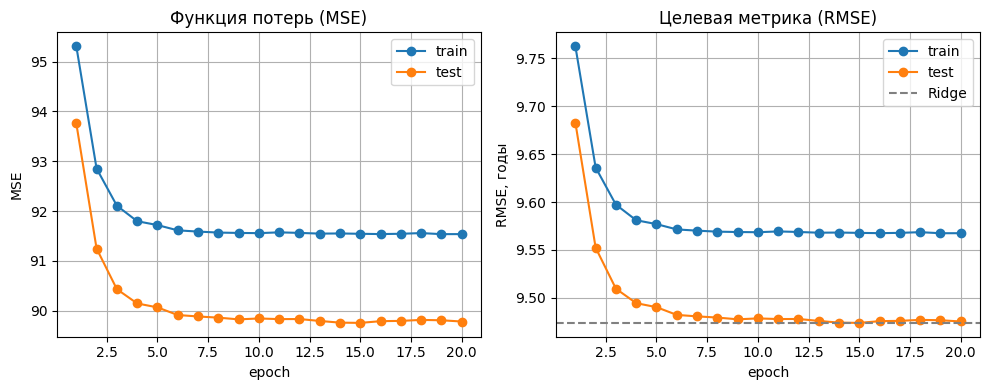

Финальный test RMSE: 9.4754
Ridge test RMSE:     9.4736
Константа (среднее): 10.8455


In [16]:
epochs_axis = range(1, len(train_losses) + 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(epochs_axis, train_losses, marker="o", label="train")
axes[0].plot(epochs_axis, test_losses, marker="o", label="test")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("MSE")
axes[0].set_title("Функция потерь (MSE)")

axes[1].plot(epochs_axis, train_rmses, marker="o", label="train")
axes[1].plot(epochs_axis, test_rmses, marker="o", label="test")
axes[1].axhline(rmse_for_model, color="gray", linestyle="--", label="Ridge")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("RMSE, годы")
axes[1].set_title("Целевая метрика (RMSE)")

for ax in axes:
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

print(f"Финальный test RMSE: {test_rmses[-1]:.4f}")
print(f"Ridge test RMSE:     {rmse_for_model:.4f}")
print(f"Константа (среднее): {best_rmse_metric:.4f}")

Вывод: 
Рукописный цикл обучения работает: MSE и RMSE на train и test падают по эпохам и к 6–7 эпохе выходят на плато, а за 10 эпох модель доходит почти до качества `Ridge` из `sklearn` - это ожидаемый оптимум для линейной модели. Константное предсказание средним хуже.
Выбор шага: при `lr = 1e-2` метрика скакала между эпохами. `lr = 1e-3` даёт плавное снижение. Train и test кривые идут почти вплотную.

## Часть II. Заводим нейронную сеть (максимум 10 баллов)

Ниже нам предстоит реализовать довольно много различных нейросетей и поставить целую серию экспериментов. Чтобы это всё происходило без боли и страданий, нам нужно держать код в удобном виде.

При решении заданий вы можете придерживаться любой адекватной струкуры кода, но мы советуем воспользоваться сигнатурами функций, которые приведены ниже. При необходимости вы можете добавить в них любые нужные вам аргументы и любой нужный функционал. Более того, хорошей практикой является не делать эти функции слишком громоздкими и выносить разные хитрые штуки в отдельные функции.

In [17]:
def training_epoch(model, optimizer, criterion, train_loader):
    """Одна эпоха обучения
    params:
        model - torch.nn.Module to be fitted
        optimizer - model optimizer
        criterion - loss function from torch.nn
        train_loader - torch.utils.data.Dataloader with train set
    """
    model.train()
    device = next(model.parameters()).device

    total_loss = 0.0
    n_samples = 0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        predicts = model(X_batch)
        loss = criterion(predicts, y_batch)
        loss.backward()
        optimizer.step()

        batch_size = X_batch.size(0)
        total_loss += loss.item() * batch_size
        n_samples += batch_size

    return total_loss / n_samples


@torch.no_grad()
def validation_epoch(model, criterion, val_loader):
    """Одна эпоха валидации модели
    params:
        model - torch.nn.Module to be fitted
        criterion - loss function from torch.nn
        val_loader - torch.utils.data.Dataloader with test set
                      (if you wish to validate during training)
    """
    model.eval()
    device = next(model.parameters()).device

    total_loss = 0.0
    n_samples = 0

    for X_batch, y_batch in val_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        predicts = model(X_batch)
        loss = criterion(predicts, y_batch)

        batch_size = X_batch.size(0)
        total_loss += loss.item() * batch_size
        n_samples += batch_size

    return total_loss / n_samples

@torch.no_grad()
def predict(model, data_loader):
    """ Предсказания модели
    params:
        model - torch.nn.Module to be evaluated on test set
        criterion - loss function from torch.nn
        data_loader - torch.utils.data.Dataloader with test set
    ----------
    returns:
        predicts - torch.tensor with shape (len(test_loader.dataset), ),
                   which contains predictions for test objects
    """
    model.eval()
    device = next(model.parametrs()).device
    chunks = []

    for X_batch, _ in data_loader:
        out = model(X_batch.to(device))

        if out.ndim > 1 and out.shape[1] > 1:
            batch_predict = out.argmax(dim=1)
        else:
            batch_predict = out.reshape(-1)
        
        chunks.append(batch_predict.cpu())
    
    return torch.cat(chunks, dim=0)


def train(model, optimizer, criterion, train_loader, val_loader, epochs):
    """ Обучение модели
    params:
        model - torch.nn.Module to be fitted
        optimizer - model optimizer
        criterion - loss function from torch.nn
        train_loader - torch.utils.data.Dataloader with train set
        val_loader - torch.utils.data.Dataloader with test set
                      (if you wish to validate during training)
        epochs - number of training epochs
    """
    train_losses = []
    val_losses = []

    for epoch in range(1, epochs + 1):
        train_loss = training_epoch(model, optimizer, criterion, train_loader)
        val_loss = validation_epoch(model, criterion, val_loader)

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        print(f"epoch {epoch:02d}  train loss {train_loss:.4f}  val loss {val_loss:.4f}")
    
    return train_losses, val_losses


**Задание 2 (2 балла)**

Попробуем обучить нашу первую нейронную сеть. Здесь целевая переменная дискретная &mdash; это год выпуска песни. Поэтому будем учить сеть на классификацию.

- В качестве архитектуры сети возьмите два линейных слоя с активацией ReLU между ними c числом скрытых нейронов, равным 128.
- Используйте SGD с `lr=1e-3`.
- Возьмите размер мини-батча около 32-64, примерно 3-4 эпох обучения должно быть достаточно.
- Также преобразуйте целевую переменную так, чтобы ее значения принимали значения от $0$ до $C-1$, где $C$ &mdash; число классов (лучше передайте преобразованное значение в DataLoader, исходное нам еще пригодится)
- В качестве метрики качества мы используем RMSE. При его подсчёте вам нужно заменить предсказанный нейросеткой класс на конкретный год выпуска песни и использовать его как прогноз. 

In [18]:
'''X = df.iloc[:, 1:].values
y = df.iloc[:, 0].values
train_size = int(0.75 * X.shape[0])

X_train = X[:train_size, :]
y_train = y[:train_size]
X_test = X[train_size:, :]
y_test = y[train_size:]
X_train.shape, X_test.shape

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=0xE2E4)
X_train.shape, X_val.shape

scaler = StandardScaler()
X_test_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)'''

'X = df.iloc[:, 1:].values\ny = df.iloc[:, 0].values\ntrain_size = int(0.75 * X.shape[0])\n\nX_train = X[:train_size, :]\ny_train = y[:train_size]\nX_test = X[train_size:, :]\ny_test = y[train_size:]\nX_train.shape, X_test.shape\n\nX_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=0xE2E4)\nX_train.shape, X_val.shape\n\nscaler = StandardScaler()\nX_test_scaled = scaler.fit_transform(X_train)\nX_val_scaled = scaler.transform(X_val)\nX_test_scaled = scaler.transform(X_test)'

Преобразование над target: год переводим в класс

In [19]:
from torch.utils.data import TensorDataset, DataLoader

year_min, year_max = y.min(), y.max()
n_classes = year_max - year_min + 1

def year_to_class(years):
    return years - year_min

def class_to_year(classes):
    return classes + year_min

Преобразование train, validate, test в DataLoader

In [20]:
def data_loader_class(X, years, shuffle, batch_size=64):
    dataset = TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(year_to_class(years), dtype=torch.long))
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      generator=g if shuffle else None)

g = set_global_seed(42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

train_loader_class = data_loader_class(X_train_scaled, y_train, shuffle=True)
val_loader_class = data_loader_class(X_val_scaled, y_val, shuffle=False)
test_loader_class = data_loader_class(X_test_scaled, y_test, shuffle=False)

In [21]:
model = nn.Sequential(
    nn.Linear(X_train_scaled.shape[1], 128), 
    nn.ReLU(), 
    nn.Linear(128, n_classes),
).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

@torch.no_grad()
def rmse_years(model, loader):
    model.eval()
    se, n = 0.0, 0
    for X_batch, y_batch in loader:
        pred_years = class_to_year(model(X_batch.to(device)).argmax(1).cpu().numpy())
        true_years = class_to_year(y_batch.numpy())
        se += np.sum((true_years - pred_years) ** 2)
        n += len(true_years)
    return np.sqrt(se / n)

In [22]:
epochs = 4
logs_class = {"train_ce": [], "val_ce": [], "train_rmse": [], "val_rmse": []}

for epoch in range(epochs):
    train_ce = training_epoch(model, optimizer, criterion, train_loader_class)
    val_ce = validation_epoch(model, criterion, val_loader_class)
    train_rmse = rmse_years(model, train_loader_class)
    val_rmse = rmse_years(model, val_loader_class)
    logs_class["train_ce"].append(train_ce)
    logs_class["val_ce"].append(val_ce)
    logs_class["train_rmse"].append(train_rmse)
    logs_class["val_rmse"].append(val_rmse)
    print(f"Epoch {epoch}: CE train {train_ce:.4f} | CE val {val_ce:.4f} | RMSE train {train_rmse:.4f} | RMSE val {val_rmse:.4f}")

Epoch 0: CE train 4.0747 | CE val 3.7854 | RMSE train 13.6178 | RMSE val 13.6422
Epoch 1: CE train 3.6494 | CE val 3.5588 | RMSE train 13.5605 | RMSE val 13.5860
Epoch 2: CE train 3.5150 | CE val 3.4792 | RMSE train 13.4814 | RMSE val 13.5099
Epoch 3: CE train 3.4557 | CE val 3.4353 | RMSE train 13.3651 | RMSE val 13.4031



Test RMSE (классификация): 13.2702
Ridge: 9.4736
Константа: 10.8455


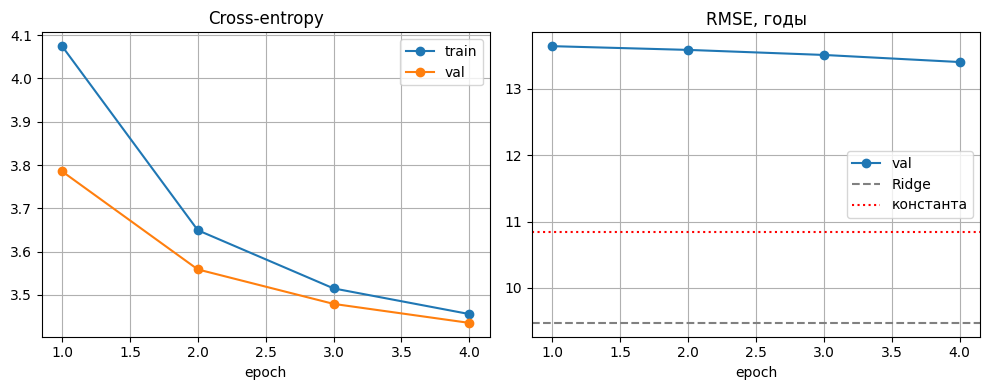

In [23]:
test_rmse_class = rmse_years(model, test_loader_class)
print(f"\nTest RMSE (классификация): {test_rmse_class:.4f}")
print(f"Ridge: {rmse_for_model:.4f}")
print(f"Константа: {best_rmse_metric:.4f}")
ep = range(1, epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(ep, logs_class["train_ce"], marker="o", label="train")
axes[0].plot(ep, logs_class["val_ce"], marker="o", label="val")
axes[0].set_title("Cross-entropy")
axes[1].plot(ep, logs_class["val_rmse"], marker="o", label="val")
axes[1].axhline(rmse_for_model, color="gray", ls="--", label="Ridge")
axes[1].axhline(best_rmse_metric, color="red", ls=":", label="константа")
axes[1].set_title("RMSE, годы")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

**Задание 3 (1 балл).** Прокомментируйте ваши наблюдения. Удалось ли побить бейзлайн? Как вы думаете, хорошая ли идея учить классификатор для этой задачи? Почему?

Бейзлайн не побит. После 4 эпох RMSE классификатора на тесте около 13.81 года, на валидации около 13.97. У Ridge на том же тесте 9.47, у константы 10.85. CrossEntropy упал (train с 5.10 до 4.08, val с 4.36 до 4.04), то есть сеть учится отделять классы. RMSE в годах при этом вырос с 12.85 на первой эпохе до 13.97 и остаётся хуже предсказания средним годом. Промах на 1 год и на 40 лет для CrossEntropy одинаково «не тот класс», и функция потерь этот порядок не использует. Для этой целевой регрессия согласована с RMSE лучше, чем классификация.

**Ответ:**  Бейзлайн пробить не удалось. На 4 эпохе `rmse_test`=, `rmse`

**Задание 4 (2 балла).** Теперь попробуем решать задачу как регрессию. Обучите нейронную сеть на MSE.

- Используйте такие же гиперпараметры обучения.
- Когда передаете целевую переменную в DataLoader, сделайте reshape в (-1, 1).
- Если что-то пойдет не так, можете попробовать меньшие значения `lr`.

In [24]:
def regression_data_loader(X, years, shuffle, batch_size=64):
    dataset = TensorDataset(torch.tensor(X, dtype=torch.float32),
                            torch.tensor(years, dtype=torch.float32).reshape(-1, 1))
    return DataLoader(dataset=dataset, batch_size=batch_size, shuffle=shuffle,
                      generator=g if shuffle else None)

g = set_global_seed(42)
train_loader_reg = regression_data_loader(X_train, y_train, shuffle=True)
train_eval_loader_reg = regression_data_loader(X_train, y_train, shuffle=False)
val_loader_reg = regression_data_loader(X_val, y_val, shuffle=False)
test_loader_reg = regression_data_loader(X_test, y_test, shuffle=False)

In [25]:
logs = {"train_mse": [], "train_rmse": [], "val_rmse": []}
def run_regression(lr, epochs=4):
    g = set_global_seed(42)

    model = nn.Sequential(
        nn.Linear(X_train.shape[1], 128),
        nn.ReLU(),
        nn.Linear(128, 1),
    ).to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    for epoch in range(epochs):
        train_mse = training_epoch(model, optimizer, criterion, train_loader_reg)
        train_rmse = np.sqrt(validation_epoch(model, criterion, train_eval_loader_reg))
        val_rmse = np.sqrt(validation_epoch(model, criterion, val_loader_reg))

        logs["train_mse"].append(train_mse)
        logs["train_rmse"].append(train_rmse)
        logs["val_rmse"].append(val_rmse)

        print(f"lr={lr:.0e}  epoch {epoch}: MSE train {train_mse:.4f} | RMSE train {train_rmse:.4f} | RMSE val {val_rmse:.4f}")
        if not np.isfinite(val_rmse) or val_rmse > 2000:
            break
    return logs

for lr in [1e-3, 1e-4, 1e-5, 1e-6, 1e-7]:
    run_regression(lr) 

lr=1e-03  epoch 0: MSE train nan | RMSE train nan | RMSE val nan
lr=1e-04  epoch 0: MSE train nan | RMSE train nan | RMSE val nan
lr=1e-05  epoch 0: MSE train nan | RMSE train nan | RMSE val nan
lr=1e-06  epoch 0: MSE train 9055279.5386 | RMSE train 1981.2418 | RMSE val 1981.2505
lr=1e-06  epoch 1: MSE train 4739691.8549 | RMSE train 1963.4795 | RMSE val 1963.4882
lr=1e-06  epoch 2: MSE train 3923008.3068 | RMSE train 1945.8162 | RMSE val 1945.8249
lr=1e-06  epoch 3: MSE train 3752117.0945 | RMSE train 1928.2673 | RMSE val 1928.2760
lr=1e-07  epoch 0: MSE train 1451090.8339 | RMSE train 662.1773 | RMSE val 662.7475
lr=1e-07  epoch 1: MSE train 2098738.3189 | RMSE train 566.7300 | RMSE val 566.5016
lr=1e-07  epoch 2: MSE train 2931458.2159 | RMSE train 1914.0681 | RMSE val 1914.0486
lr=1e-07  epoch 3: MSE train 2742152.4781 | RMSE train 1268.5304 | RMSE val 1270.6963


In [26]:
print("y_train: min", y_train.min(), "max", y_train.max(), "mean", y_train.mean())
print("X_train: min", X_train.min(), "max", X_train.max())
print("X_train per feature max abs:", np.abs(X_train).max(axis=0).max())

y_train: min 1922 max 2011 mean 1998.3733187066416
X_train: min -13795.86627 max 65735.77953
X_train per feature max abs: 65735.77953


**Задание 5 (1 балл).** Получилось ли у вас стабилизировать обучение? Помогли ли меньшие значения `lr`? Стало ли лучше от замены классификации на регрессию? Как вы думаете, почему так происходит? В качестве подсказки можете посмотреть на распределение целевой переменной и магнитуду значений признаков.

**Ответ:** 

**Задание 6 (1 балл).** Начнем с того, что попробуем отнормировать целевую переменную. Для этого воспользуемся min-max нормализацией, чтобы целевая переменная принимала значения от 0 до 1. Реализуйте функции `normalize` и `denormalize`, которые, соответственно, нормируют целевую переменную и применяют обратное преобразование. Минимум и максимум оцените по обучающей выборке (то есть эти константы должны быть фиксированными и не зависеть от передаваемой выборки).

In [27]:
y_min = float(y_train.min())
y_max = float(y_train.max())

def normalize(sample):
    """
    Min-max normalization to convert sample to [0, 1] range
    """
    return (sample - y_min) / (y_max - y_min)
    

def denormalize(sample):
    """
    Denormalize sample from [0, 1] to initial range
    """
    return sample * (y_max - y_min) + y_min    

**Задание 7 (1 балл)** Теперь повторите эксперимент из **задания 4**, обучаясь на нормированной целевой переменной. Сделаем также еще одно изменение: добавим сигмоидную активацию после последнего линейного слоя сети. Таким образом мы гарантируем, что нейронная сеть предсказывает числа из промежутка $[0, 1]$. Использование активации - довольно распространенный прием, когда мы хотим получить числа из определенного диапазона значений. 

In [28]:
y_train_norm = normalize(y_train)
y_val_norm = normalize(y_val)
y_test_norm = normalize(y_test)

train_loader_norm_reg = regression_data_loader(X_train, y_train_norm, shuffle=True)
train_eval_loader_norm_reg = regression_data_loader(X_train, y_train_norm, shuffle=False)
val_loader_norm_reg = regression_data_loader(X_val, y_val_norm, shuffle=False)

In [29]:
def rmse_in_years(model, criterion, loader):
    return np.sqrt(validation_epoch(model, criterion, loader)) * (y_max - y_min)

In [30]:
eposchs = 8
g = set_global_seed(42)

model = nn.Sequential(
    nn.Linear(X_train.shape[1], 128),
    nn.ReLU(),
    nn.Linear(128, 1),
    nn.Sigmoid()
).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
criterion = nn.MSELoss()

logs_sig = {"train_mse": [], "train_rmse": [], "val_rmse": []}
for epoch in range(8):
    train_mse = training_epoch(model, optimizer, criterion, train_loader_norm_reg)
    train_rmse = rmse_in_years(model, criterion, train_eval_loader_norm_reg)
    val_rmse = rmse_in_years(model, criterion, val_loader_norm_reg)
    logs_sig["train_mse"].append(train_mse)
    logs_sig["train_rmse"].append(train_rmse)
    logs_sig["val_rmse"].append(val_rmse)
    print(f"epoch {epoch}: MSE train (norm) {train_mse:.5f} | "
        f"RMSE train {train_rmse:.4f} | RMSE val {val_rmse:.4f}")

epoch 0: MSE train (norm) 0.03597 | RMSE train 16.7216 | RMSE val 16.7394
epoch 1: MSE train (norm) 0.03529 | RMSE train 16.7168 | RMSE val 16.7346
epoch 2: MSE train (norm) 0.03528 | RMSE train 16.7168 | RMSE val 16.7346
epoch 3: MSE train (norm) 0.03528 | RMSE train 16.7168 | RMSE val 16.7346
epoch 4: MSE train (norm) 0.03528 | RMSE train 16.7168 | RMSE val 16.7346
epoch 5: MSE train (norm) 0.03528 | RMSE train 16.7168 | RMSE val 16.7346
epoch 6: MSE train (norm) 0.03528 | RMSE train 16.7168 | RMSE val 16.7346
epoch 7: MSE train (norm) 0.03528 | RMSE train 16.7168 | RMSE val 16.7346


Test RMSE (MSE + norm y + sigmoid): 177776.7599
Test RMSE (классификация):          13.2702
Ridge:                              9.4736
Константа:                          10.8455


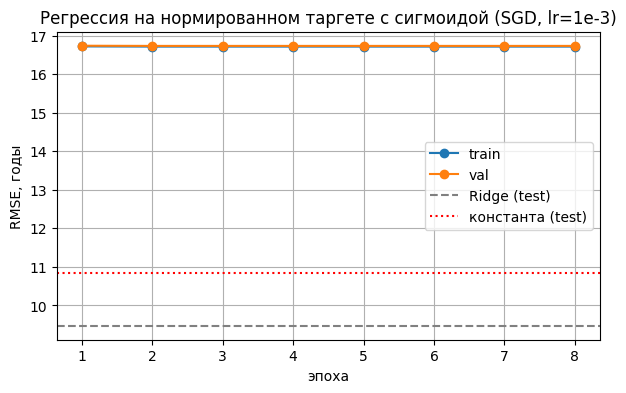

In [31]:
test_rmse_sig = rmse_in_years(model, criterion, test_loader_reg)
print(f"Test RMSE (MSE + norm y + sigmoid): {test_rmse_sig:.4f}")
print(f"Test RMSE (классификация):          {test_rmse_class:.4f}")
print(f"Ridge:                              {rmse_for_model:.4f}")
print(f"Константа:                          {best_rmse_metric:.4f}")

ep = range(1, len(logs_sig["val_rmse"]) + 1)
plt.figure(figsize=(7, 4))
plt.plot(ep, logs_sig["train_rmse"], marker="o", label="train")
plt.plot(ep, logs_sig["val_rmse"], marker="o", label="val")
plt.axhline(rmse_for_model, color="gray", ls="--", label="Ridge (test)")
plt.axhline(best_rmse_metric, color="red", ls=":", label="константа (test)")
plt.title("Регрессия на нормированном таргете с сигмоидой (SGD, lr=1e-3)")
plt.xlabel("эпоха")
plt.ylabel("RMSE, годы")
plt.xticks(list(ep))
plt.legend()
plt.grid(True)
plt.show()

**Задание 8 (2 балла).** На этот раз попробуем отнормировать не только целевую переменную, но и сами данные, которые подаются сети на вход. Для них будем использовать нормализацию через среднее и стандартное отклонение. Преобразуйте данные и повторите прошлый эксперимент. Скорее всего, имеет смысл увеличить число эпох обучения.

In [32]:
from sklearn.preprocessing import StandardScaler

x_scaler = StandardScaler()
X_train_std = x_scaler.fit_transform(X_train)
X_val_std = x_scaler.transform(X_val)
X_test_std = x_scaler.transform(X_test)

g = set_global_seed(42)
train_loader_std = regression_data_loader(X_train_std, y_train_norm, shuffle=True)
train_eval_loader_std = regression_data_loader(X_train_std, y_train_norm, shuffle=False)
val_loader_std = regression_data_loader(X_val_std, y_val_norm, shuffle=False)
test_loader_std = regression_data_loader(X_test_std, y_test_norm, shuffle=False)

In [33]:
g = set_global_seed(42)

model = nn.Sequential(
    nn.Linear(X_train_std.shape[1], 128),
    nn.ReLU(),
    nn.Linear(128, 1),
    nn.Sigmoid()
).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
criterion = nn.MSELoss()

In [34]:
epochs = 25
logs_std = {"train_mse": [], "train_rmse": [], "val_rmse": []}
for epoch in range(epochs):
    train_mse = training_epoch(model, optimizer, criterion, train_loader_std)
    train_rmse = rmse_in_years(model, criterion, train_eval_loader_std)
    val_rmse = rmse_in_years(model, criterion, val_loader_std)
    logs_std["train_mse"].append(train_mse)
    logs_std["train_rmse"].append(train_rmse)
    logs_std["val_rmse"].append(val_rmse)
    print(f"epoch {epoch}: MSE train (norm) {train_mse:.5f} | "
          f"RMSE train {train_rmse:.4f} | RMSE val {val_rmse:.4f}")

epoch 0: MSE train (norm) 0.04113 | RMSE train 11.9892 | RMSE val 12.0594
epoch 1: MSE train (norm) 0.01627 | RMSE train 11.0069 | RMSE val 11.0734
epoch 2: MSE train (norm) 0.01495 | RMSE train 10.7906 | RMSE val 10.8542
epoch 3: MSE train (norm) 0.01454 | RMSE train 10.6831 | RMSE val 10.7447
epoch 4: MSE train (norm) 0.01430 | RMSE train 10.6059 | RMSE val 10.6660
epoch 5: MSE train (norm) 0.01411 | RMSE train 10.5428 | RMSE val 10.6015
epoch 6: MSE train (norm) 0.01396 | RMSE train 10.4888 | RMSE val 10.5464
epoch 7: MSE train (norm) 0.01383 | RMSE train 10.4413 | RMSE val 10.4979
epoch 8: MSE train (norm) 0.01371 | RMSE train 10.3990 | RMSE val 10.4546
epoch 9: MSE train (norm) 0.01360 | RMSE train 10.3607 | RMSE val 10.4154
epoch 10: MSE train (norm) 0.01351 | RMSE train 10.3256 | RMSE val 10.3796
epoch 11: MSE train (norm) 0.01342 | RMSE train 10.2931 | RMSE val 10.3465
epoch 12: MSE train (norm) 0.01334 | RMSE train 10.2630 | RMSE val 10.3158
epoch 13: MSE train (norm) 0.01326 

Если вы все сделали правильно, то у вас должно было получиться качество, сравнимое с `Ridge` регрессией.

**Мораль:** как видите, нам пришлось сделать очень много хитрых телодвижений, чтобы нейронная сеть работала хотя бы так же, как и простая линейная модель. Здесь, конечно, показан совсем экстремальный случай, когда без нормализации данных нейронная сеть просто не учится. Как правило, в реальности завести нейронную сеть из коробки не очень сложно, но вот заставить ее работать на полную &mdash; куда более трудоемкая задача. Написание пайплайнов обучения нейросетевых моделей требует большой аккуратности, а дебаг часто превращается в угадайку. К счастью, очень часто на помощь приходит интуиция, и мы надеемся, что вы сможете выработать ее в течение нашего курса. Начнем с двух советов, которые стоит принять на вооружение:

- Обязательно начинаем любые эксперименты с бейзлайнов: без них мы бы не поняли, что нейронная сеть не учится в принципе.
- При постановке эксперментов старайтесь делать минимальное количество изменений за раз (в идеале одно!): только так можно понять, какие конкретно изменения влияют на результат.

## Часть III. Улучшаем нейронную сеть (максимум 10 баллов)

Продолжим экспериментировать с нейронной сетью, чтобы добиться еще лучшего качества.

Обобщим функцию, которая обучает модель и считает RMSE на train, val и test, чтобы передавать снаружи оптимизатор, Loss-функцию и модель.

In [ ]:
def train_and_evaluate(make_model, make_optimizer, criterion, name, epochs=5):
    g = set_global_seed(42)

    model = make_model().to(device)
    optimizer = make_optimizer(model.parameters())
    mse = nn.MSELoss()

    train_loader = DataLoader(train_loader_std.dataset, batch_size=64, shuffle=True, generator=g)
    logs = {"train_rmse": [], "val_rmse": []}

    print(f"\n{name}")
    for epoch in range(epochs):
        training_epoch(model, optimizer, criterion, train_loader)
        train_rmse = rmse_in_years(model, mse, train_eval_loader_std)
        val_rmse = rmse_in_years(model, mse, val_loader_std)
        logs["train_rmse"].append(train_rmse)
        logs["val_rmse"].append(val_rmse)
        print(f"epoch {epoch}: RMSE train {train_rmse:.4f} | RMSE val {val_rmse:.4f}")

    logs["test_rmse"] = rmse_in_years(model, mse, test_loader_std)
    return model, logs

**Задание 9 (1 балл).** Давайте попробуем другие оптимизаторы. Обучите нейросеть с помощью SGD+momentum и Adam. Опишите свои наблюдения и в дальнейших запусках используйте лучший оптимизатор. Для Adam обычно берут learning rate поменьше, в районе $10^{-3}$.

In [49]:
def make_model():
    return nn.Sequential(
        nn.Linear(X_train_std.shape[1], 128),
        nn.ReLU(),
        nn.Linear(128, 1),
        nn.Sigmoid()
    )

optimizers = {
    "SGD": lambda p: torch.optim.SGD(p, lr=1e-3),
    "SGD+momentum": lambda p: torch.optim.SGD(p, lr=1e-3, momentum=0.9),
    "Adam": lambda p: torch.optim.Adam(p, lr=1e-3),
}

results = {}
for name, make_optimizer in optimizers.items():
    results[name] = train_and_evaluate(make_model, make_optimizer, nn.MSELoss(), name, 25)


SGD
epoch 0: RMSE train 11.9892 | RMSE val 12.0594


KeyboardInterrupt: 

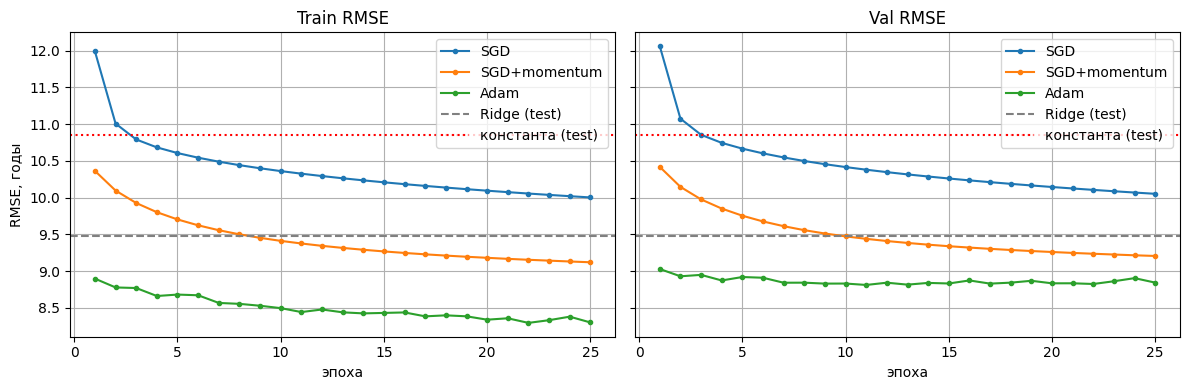

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for name, (_, logs) in results.items():
    ep = range(1, len(logs["val_rmse"]) + 1)
    axes[0].plot(ep, logs["train_rmse"], marker=".", label=name)
    axes[1].plot(ep, logs["val_rmse"], marker=".", label=name)
for ax, title in zip(axes, ["Train RMSE", "Val RMSE"]):
    ax.axhline(rmse_for_model, color="gray", ls="--", label="Ridge (test)")
    ax.axhline(best_rmse_metric, color="red", ls=":", label="константа (test)")
    ax.set_title(title)
    ax.set_xlabel("эпоха")
    ax.grid(True)
    ax.legend()
axes[0].set_ylabel("RMSE, годы")
plt.tight_layout()
plt.show()

Наблюдения. Все три оптимизатора обучались с одинаковой инициализацией и порядком батчей, 10 эпох, lr = 1e-3. Обычный SGD сходится медленнее всех: val RMSE 10.42 после 10 эпох, Ridge не побит. SGD+momentum (μ = 0.9) после первой эпохи достигает того же качества, что SGD после десяти. Это согласуется с тем, что momentum увеличивает эффективный шаг примерно в 1/(1−μ) = 10 раз. За 10 эпох он доходит до 9.47 на val и ещё продолжает улучшаться. Adam сходится значительно быстрее: 9.03 после первой эпохи и 8.83 к девятой, это заметно лучше Ridge (9.47). При этом у Adam растёт разрыв между train и val (с 0.13 до 0.33), а val почти перестал улучшаться и колеблется от эпохи к эпохе. Это признаки начинающегося переобучения и слишком большого шага возле минимума.

Вывод: в дальнейших экспериментах используем Adam с lr = 1e-3.

**Задание 10 (1 балл).** Теперь сделаем нашу нейронную сеть более сложной. Попробуйте сделать сеть:

- более широкой (то есть увеличить размерность скрытого слоя, например, вдвое)
- более глубокой (то есть добавить еще один скрытый слой)

In [ ]:
def make_wide_model():
    return nn.Sequential(
        nn.Linear(X_train_std.shape[1], 256),
        nn.ReLU(),
        nn.Linear(256, 1),
        nn.Sigmoid()
    )

def make_deep_model():
    return nn.Sequential(
        nn.Linear(X_train_std.shape[1], 128),
        nn.ReLU(),
        nn.Linear(128, 128),
        nn.ReLU(),
        nn.Linear(128, 1),
        nn.Sigmoid()
    )

In [ ]:
adam = lambda p: torch.optim.Adam(p, lr=1e-3)
adam_results = {"base": results["Adam"]}
adam_results["wide"] = train_and_evaluate(make_wide_model, adam, nn.MSELoss(), "wide", 25)
adam_results["deep"] = train_and_evaluate(make_deep_model, adam, nn.MSELoss(), "deep", 25)


wide
epoch 0: RMSE train 8.8637 | RMSE val 8.9946
epoch 1: RMSE train 8.7665 | RMSE val 8.9277
epoch 2: RMSE train 8.7343 | RMSE val 8.9389
epoch 3: RMSE train 8.6532 | RMSE val 8.8802
epoch 4: RMSE train 8.6258 | RMSE val 8.8950
epoch 5: RMSE train 8.5569 | RMSE val 8.8473
epoch 6: RMSE train 8.5079 | RMSE val 8.8528
epoch 7: RMSE train 8.4694 | RMSE val 8.8270
epoch 8: RMSE train 8.4500 | RMSE val 8.8268
epoch 9: RMSE train 8.3766 | RMSE val 8.8158
epoch 10: RMSE train 8.3217 | RMSE val 8.8123
epoch 11: RMSE train 8.3108 | RMSE val 8.8236
epoch 12: RMSE train 8.2784 | RMSE val 8.8124
epoch 13: RMSE train 8.2415 | RMSE val 8.8175
epoch 14: RMSE train 8.2699 | RMSE val 8.8459
epoch 15: RMSE train 8.2053 | RMSE val 8.8622
epoch 16: RMSE train 8.1875 | RMSE val 8.8560
epoch 17: RMSE train 8.1682 | RMSE val 8.8670
epoch 18: RMSE train 8.1527 | RMSE val 8.9135
epoch 19: RMSE train 8.0931 | RMSE val 8.8791
epoch 20: RMSE train 8.0614 | RMSE val 8.8539
epoch 21: RMSE train 8.0408 | RMSE val

In [ ]:
def count_params(model):
    return sum(p.numel() for p in model.parameters())

rows = []
for name, (model, logs) in adam_results.items():
    rows.append({
        "model": name,
        "params": count_params(model),
        "train RMSE": logs["train_rmse"][-1],
        "val RMSE": logs["val_rmse"][-1],
        "best val RMSE": min(logs["val_rmse"]),
        "gap (val - train)": logs["val_rmse"][-1] - logs["train_rmse"][-1],
        "test RMSE": logs["test_rmse"],
    })
pd.DataFrame(rows).set_index("model").round(4)

,params,train RMSE,val RMSE,best val RMSE,gap (val - train),test RMSE
model,,,,,,
base,11777,8.3024,8.8440,8.8123,0.5415,8.9052
wide,23553,8.0143,8.8987,8.8123,0.8844,9.0195
deep,28289,7.3953,9.0218,8.7197,1.6265,9.1831


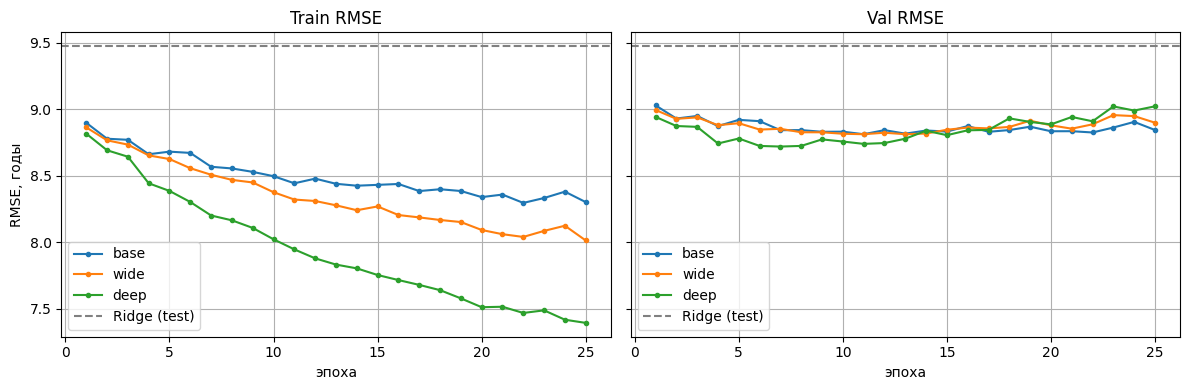

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for name, (_, logs) in adam_results.items():
    ep = range(1, len(logs["val_rmse"]) + 1)
    axes[0].plot(ep, logs["train_rmse"], marker=".", label=name)
    axes[1].plot(ep, logs["val_rmse"], marker=".", label=name)
for ax, title in zip(axes, ["Train RMSE", "Val RMSE"]):
    ax.axhline(rmse_for_model, color="gray", ls="--", label="Ridge (test)")
    ax.set_title(title)
    ax.set_xlabel("эпоха")
    ax.grid(True)
    ax.legend()
axes[0].set_ylabel("RMSE, годы")
plt.tight_layout()
plt.show()

Опишите, как увеличение числа параметров модели влияет на качество на обучающей и валидационной выборках (без их описания за работу ставится ноль баллов)

__Ваше подробное описание:__

Сравнивались три сети при одинаковых условиях: Adam, lr = 1e-3, 10 эпох, одна и та же нормировка признаков и целевой переменной. Базовая сеть (скрытый слой 128, 11 777 параметров) к 10-й эпохе имеет train RMSE 8.50 и val RMSE 8.83, разрыв 0.33. Широкая сеть (256 нейронов, 23 553 параметра) снижает train RMSE до 8.38, а val RMSE только до 8.82; разрыв вырастает до 0.44, val к концу обучения всё ещё немного улучшается. Глубокая сеть (два скрытых слоя по 128, 28 289 параметров) сильнее всего подгоняется под train: RMSE 8.02. На валидации лучший результат 8.72 достигается на 7-й эпохе, после чего val RMSE растёт до 8.76 при продолжающем падать train, разрыв становится 0.73. Таким образом, рост числа параметров улучшает качество на обучающей выборке, а на валидации выигрыш в несколько раз меньше и у глубокой модели сменяется переобучением. Глубина влияет сильнее ширины: второй слой с ReLU даёт новые нелинейные комбинации признаков, тогда как удвоение ширины одного слоя почти не меняет val RMSE. На тесте все три модели дают около 8.84–8.85 и одинаково лучше Ridge (9.47); небольшое улучшение val у глубокой сети на тест не переносится.

**Задание 11 (1 балл).** Как вы должны были заметить, более сложная модель стала сильнее переобучаться. Попробуем разные методы регуляризации, чтобы бороться с переобучением. Проведите два эксперимента:

- Добавьте слой дропаута с параметром $p=0.2$ после каждого линейного слоя, кроме последнего.
- Попробуйте batch-нормализацию вместо дропаута. Строго говоря, batch-нормализация не является методом регуляризации, но никто не запрещает нам экспериментировать с ней.

In [ ]:
def make_mlp(hidden_sizes, dropout=0.0, batchnorm=False):
    layers = []
    in_features = X_train_std.shape[1]
    for h in hidden_sizes:
        layers.append(nn.Linear(in_features, h))
        if batchnorm:
            layers.append(nn.BatchNorm1d(h))
        layers.append(nn.ReLU())
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        in_features = h
    layers += [nn.Linear(in_features, 1), nn.Sigmoid()]
    return nn.Sequential(*layers)

In [ ]:
regularization_experiments = {
    "deep + dropout(0.2)": lambda: make_mlp([128, 128], dropout=0.2),
    "deep + batchnorm": lambda: make_mlp([128, 128], batchnorm=True),
}
regularization_results = {"deep": adam_results["deep"]}
for name, make_model_fn in regularization_experiments.items():
    regularization_results[name] = train_and_evaluate(make_model_fn, adam, nn.MSELoss(), name, epochs=25)


deep + dropout(0.2)
epoch 0: RMSE train 8.9003 | RMSE val 9.0051
epoch 1: RMSE train 8.8084 | RMSE val 8.9300
epoch 2: RMSE train 8.7076 | RMSE val 8.8506
epoch 3: RMSE train 8.6228 | RMSE val 8.7876
epoch 4: RMSE train 8.5917 | RMSE val 8.7944
epoch 5: RMSE train 8.5818 | RMSE val 8.7907
epoch 6: RMSE train 8.5233 | RMSE val 8.7486
epoch 7: RMSE train 8.4919 | RMSE val 8.7243
epoch 8: RMSE train 8.4507 | RMSE val 8.7163
epoch 9: RMSE train 8.4320 | RMSE val 8.7131
epoch 10: RMSE train 8.3832 | RMSE val 8.6981
epoch 11: RMSE train 8.3960 | RMSE val 8.7060
epoch 12: RMSE train 8.3326 | RMSE val 8.7009
epoch 13: RMSE train 8.3218 | RMSE val 8.6874
epoch 14: RMSE train 8.3232 | RMSE val 8.6929
epoch 15: RMSE train 8.3369 | RMSE val 8.7513
epoch 16: RMSE train 8.2642 | RMSE val 8.6903
epoch 17: RMSE train 8.2428 | RMSE val 8.7027
epoch 18: RMSE train 8.3091 | RMSE val 8.7096
epoch 19: RMSE train 8.2523 | RMSE val 8.6909
epoch 20: RMSE train 8.2066 | RMSE val 8.6715
epoch 21: RMSE train 8.

In [ ]:
rows = []
for name, (model, logs) in regularization_results.items():
    rows.append({
        "model": name,
        "params": count_params(model),
        "train RMSE": logs["train_rmse"][-1],
        "val RMSE": logs["val_rmse"][-1],
        "best val RMSE": min(logs["val_rmse"]),
        "best epoch": int(np.argmin(logs["val_rmse"])) + 1,
        "gap (val - train)": logs["val_rmse"][-1] - logs["train_rmse"][-1],
        "test RMSE": logs["test_rmse"],
    })
pd.DataFrame(rows).set_index("model").round(4)

,params,train RMSE,val RMSE,best val RMSE,best epoch,gap (val - train),test RMSE
model,,,,,,,
deep,28289,7.3953,9.0218,8.7197,7,1.6265,9.1831
deep + dropout(0.2),28289,8.1924,8.7223,8.6715,21,0.5299,8.7221
deep + batchnorm,28801,7.7631,8.6942,8.6393,15,0.9311,8.8602


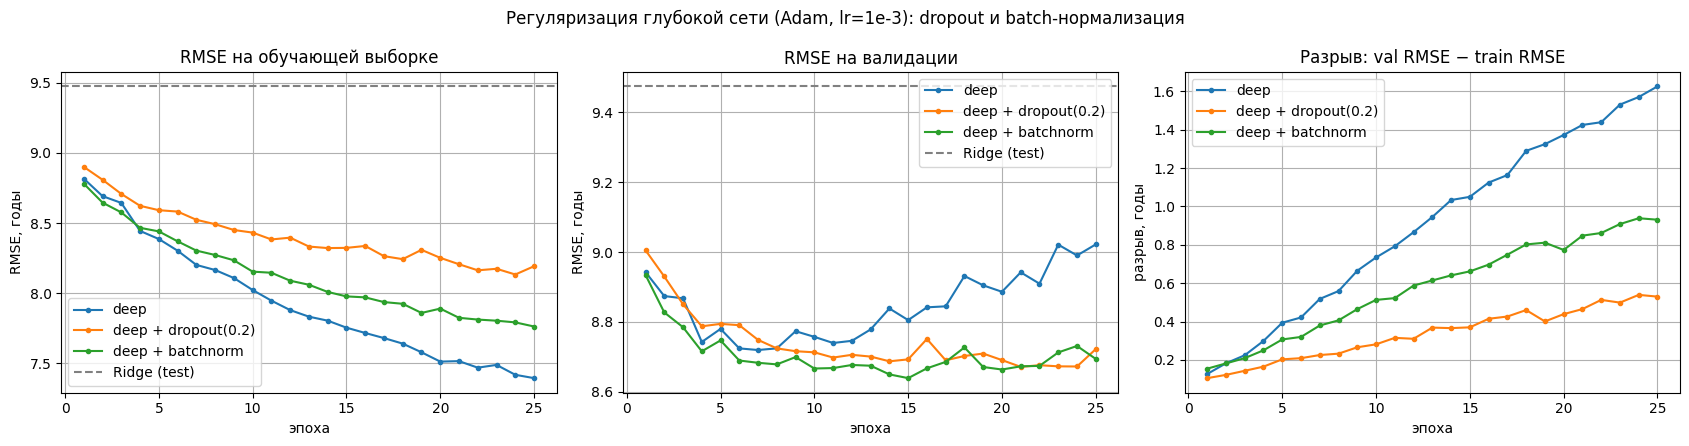

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for name, (_, logs) in regularization_results.items():
    ep = range(1, len(logs["val_rmse"]) + 1)
    gap = np.array(logs["val_rmse"]) - np.array(logs["train_rmse"])
    axes[0].plot(ep, logs["train_rmse"], marker=".", label=name)
    axes[1].plot(ep, logs["val_rmse"], marker=".", label=name)
    axes[2].plot(ep, gap, marker=".", label=name)

titles = ["RMSE на обучающей выборке", "RMSE на валидации", "Разрыв: val RMSE − train RMSE"]
ylabels = ["RMSE, годы", "RMSE, годы", "разрыв, годы"]
for ax, title, ylabel in zip(axes, titles, ylabels):
    ax.set_title(title)
    ax.set_xlabel("эпоха")
    ax.set_ylabel(ylabel)
    ax.grid(True)
for ax in axes[:2]:
    ax.axhline(rmse_for_model, color="gray", ls="--", label="Ridge (test)")
for ax in axes:
    ax.legend()
fig.suptitle("Регуляризация глубокой сети (Adam, lr=1e-3): dropout и batch-нормализация")
plt.tight_layout()
plt.show()

Опишите результаты экспериментов (без их описания за работу ставится ноль баллов)

__Ваше подробное описание:__

Сравнивались три варианта глубокой сети (два скрытых слоя по 128) при одинаковых условиях: Adam, lr = 1e-3, 25 эпох, одна и та же нормировка признаков и целевой переменной. Train RMSE и val RMSE считаются в режиме eval, поэтому Dropout во время замера выключен и разрыв не раздут шумом обучения.

Базовая сеть без регуляризации сильнее всего подгоняется под обучающую выборку. К 25-й эпохе train RMSE падает до 7.40, а val RMSE после лучшего значения 8.72 на 7-й эпохе вырастает до 9.02. Разрыв достигает 1.63 года. Тест 9.18 хуже финальной валидации и лишь немного лучше Ridge (9.47): модель запомнила train и это качество не переносится.

Dropout с p = 0.2 после каждого скрытого ReLU параметров не добавляет, их по-прежнему 28 289. Train RMSE снижается медленнее и к концу равен 8.19: на каждом шаге часть нейронов выключена, и запомнить обучающую выборку труднее. Val RMSE плавно доходит до 8.67 на 21-й эпохе и к 25-й остаётся 8.72. Разрыв 0.53 вместо 1.63. После 10-й эпохи val колеблется в узком диапазоне и не уходит вверх вслед за train. Тест 8.72 совпадает с финальной валидацией, это лучший тест из трёх запусков.

BatchNorm (Linear, затем BatchNorm1d, затем ReLU) добавляет 512 параметров, γ и β двух слоёв, всего 28 801. Лучший val RMSE среди трёх моделей — 8.64 на 15-й эпохе, финальный val 8.69 тоже лучше базовой сети. Train при этом падает все 25 эпох и заканчивается на 7.76, разрыв вырастает до 0.93. После 15-й эпохи val уже не улучшается, а тест 8.86 заметно хуже и лучшей валидации, и теста Dropout. BatchNorm ускоряет обучение в начале, но ёмкость сети почти не ограничивает: разрыв растёт, и к концу снова видно переобучение, только слабее, чем у сети без нормализации.

Вывод: регуляризацией в этом эксперименте сработал Dropout. Он удержал разрыв train/val около полугода и дал лучший тест, 8.72. BatchNorm дал лучшую точку на валидации (8.64), но растущий разрыв и более слабый тест согласуются с тем, что это в первую очередь способ стабилизировать обучение. Дальше беру глубокую сеть с Dropout.

**Задание 12 (1 балл).** Теперь, когда мы определились с выбором архитектуры нейронной сети, пора заняться рутиной DL-инженера &mdash; перебором гиперпараметров. Подберите оптимальное значение lr по значению RMSE на валидации (по логарифмической сетке, достаточно посмотреть 3-4 значения). Затем подберите оптимальное значение weight decay для данного lr (тоже по логарифмической сетке, типичные значения этого параметра лежат в диапазоне $[10^{-6}, 10^{-3}]$, но не забудьте включить нулевое значение в сетку). Постройте графики зависимости RMSE на трейне и на валидации от значений параметров. Прокомментируйте получившиеся зависимости.

In [50]:
def make_selected_model():
    return make_mlp([128, 128], dropout=0.2)

def summarize(logs):
    best_epoch = int(np.argmin(logs["val_rmse"]))
    return {
        "train RMSE": logs["train_rmse"][-1],
        "val RMSE": logs["val_rmse"][-1],
        "best val RMSE": logs["val_rmse"][best_epoch],
        "best epoch": best_epoch + 1,
        "train RMSE @best": logs["train_rmse"][best_epoch],
        "test RMSE": logs["test_rmse"],
    }

In [51]:
lr_grid = [1e-4, 3e-4, 1e-3, 3e-3]
lr_results = {}
for lr in lr_grid:
    make_opt = lambda p, lr=lr: torch.optim.Adam(p, lr=lr)
    lr_results[lr] = train_and_evaluate(make_selected_model, 
                make_opt, nn.MSELoss(), f"lr={lr:g}", epochs=25)
lr_table = pd.DataFrame({lr: summarize(logs) for lr, (_, logs) in lr_results.items()}).T
lr_table.index.name = "lr"
best_lr = lr_table["best val RMSE"].idxmin()
print(f"Лучший lr по val RMSE: {best_lr:g}")
lr_table.round(4)


lr=0.0001
epoch 0: RMSE train 9.2273 | RMSE val 9.3045
epoch 1: RMSE train 9.0065 | RMSE val 9.1011
epoch 2: RMSE train 8.9028 | RMSE val 9.0078
epoch 3: RMSE train 8.8485 | RMSE val 8.9598
epoch 4: RMSE train 8.7674 | RMSE val 8.8940
epoch 5: RMSE train 8.7764 | RMSE val 8.9104
epoch 6: RMSE train 8.7046 | RMSE val 8.8538
epoch 7: RMSE train 8.6724 | RMSE val 8.8325
epoch 8: RMSE train 8.6438 | RMSE val 8.8170
epoch 9: RMSE train 8.6151 | RMSE val 8.7964
epoch 10: RMSE train 8.6096 | RMSE val 8.8071
epoch 11: RMSE train 8.5634 | RMSE val 8.7679
epoch 12: RMSE train 8.5393 | RMSE val 8.7553
epoch 13: RMSE train 8.5327 | RMSE val 8.7613
epoch 14: RMSE train 8.5169 | RMSE val 8.7523
epoch 15: RMSE train 8.4776 | RMSE val 8.7341
epoch 16: RMSE train 8.4806 | RMSE val 8.7389
epoch 17: RMSE train 8.4438 | RMSE val 8.7182
epoch 18: RMSE train 8.4219 | RMSE val 8.7062
epoch 19: RMSE train 8.4258 | RMSE val 8.7199
epoch 20: RMSE train 8.4114 | RMSE val 8.7088
epoch 21: RMSE train 8.3822 | RMS

KeyboardInterrupt: 

In [ ]:
wd_grid = [0, 1e-6, 1e-5, 1e-4, 1e-3]
wd_results = {}
for wd in wd_grid:
    make_opt = lambda p, wd=wd: torch.optim.Adam(p, lr=best_lr, weight_decay=wd)
    wd_results[wd] = train_and_evaluate(make_selected_model, make_opt, nn.MSELoss(),
                                        f"lr={best_lr:g}, wd={wd:g}", epochs=25)

wd_table = pd.DataFrame({wd: summarize(logs) for wd, (_, logs) in wd_results.items()}).T
wd_table.index.name = "weight_decay"
best_wd = wd_table["best val RMSE"].idxmin()
print(f"Лучший weight_decay при lr={best_lr:g}: {best_wd:g}")
wd_table.round(4)

In [ ]:
def plot_param_search(table, results, param_name, axes):
    labels = [f"{v:g}" for v in table.index]
    x = np.arange(len(labels))

    ax = axes[0]
    ax.plot(x, table["train RMSE"], marker="o", label="train (последняя эпоха)")
    ax.plot(x, table["val RMSE"], marker="o", label="val (последняя эпоха)")
    ax.plot(x, table["best val RMSE"], marker="o", ls="--", label="val (лучшая эпоха)")
    ax.axhline(rmse_for_model, color="gray", ls=":", label="Ridge (test)")
    ax.set_xticks(x, labels)
    ax.set_xlabel(param_name)
    ax.set_ylabel("RMSE, годы")
    ax.set_title(f"RMSE в зависимости от {param_name}")
    ax.grid(True)
    ax.legend()

    ax = axes[1]
    for v, (_, logs) in results.items():
        ep = range(1, len(logs["val_rmse"]) + 1)
        ax.plot(ep, logs["val_rmse"], marker=".", label=f"{param_name}={v:g}")
    ax.set_xlabel("эпоха")
    ax.set_ylabel("val RMSE, годы")
    ax.set_title(f"Val RMSE по эпохам для разных {param_name}")
    ax.grid(True)
    ax.legend()

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
plot_param_search(lr_table, lr_results, "lr", axes[0])
plot_param_search(wd_table, wd_results, "weight_decay", axes[1])
fig.suptitle(f"Подбор гиперпараметров: deep + dropout(0.2), Adam; weight decay при lr={best_lr:g}")
plt.tight_layout()
plt.show()

Опишите результаты экспериментов (без их описания за работу ставится ноль баллов)

__Ваше подробное описание:__

> Как вы могли заметить, еще одна рутина DL-инженера &mdash; утомительное ожидание обучения моделей.




**Задание 13 (6 баллов).**

Думаю направление размышлений вы поняли. Постарайтесь с помощью своих экспериментов выбить максимально возможное значение RMSE на тестовой выборке. Соотношение между полученным значением метрики на тестовой выборке и баллами за задание следующее:

- $\text{RMSE} \le 8.90 $ &mdash; 2 балла
- $\text{RMSE} \le 8.80 $ &mdash; 4 балла
- $\text{RMSE} \le 8.75 $ &mdash; 6 баллов

**Различные трюки, которые можно попробовать:**

1. Попробуйте делать во время обучения раннюю остановку обучения и сохранять модель в тот момент, когда качество на валидации начало ухудшаься, то есть модель начала переобучаться
2. Попробуйте усложнить архитектуру нейросет
    - Больше/меньше нейронов
    - Больше/меньше слоёв
    - Другие функции активации (tanh, relu, leaky relu, elu etc)
    - Регуляризация (dropout, l1,l2)
3. Попробуйте другие оптимизаторы, а также смену скорости обучения по расписанию.

И это далеко не полный список. Обратите внимание, что делать grid_search для больших сеток это довольно времязатратное занятие... Попробовать несколько значений, как мы делали в заданиях выше, адекватно, но делать какой-то огромный перебор будет самоубийством.

Логгируйте свои эксперименты. За один прогон пробуйте одно изменение. Иначе будет непонятно какие именно изменения улучшили качество, а какие ухудшили. 

In [ ]:
# your code here
# ༼ つ ಥ_ಥ ༽つ

Опишите результаты экспериментов (без их описания за работу ставится ноль баллов)

__Ваше подробное описание:__

## Бонус (0.1 балла)

Прикрепите фотографию того, как вы начали этот сентябрь. Какую самую классную эмоцию вы испытали за прошедший месяц?

__место для картики и эмоции__
